In [3]:
from mayavi import mlab
import pandas as pd
import numpy as np
import os
import nibabel as nb
from matplotlib import pyplot as plt
import matplotlib
from scipy.ndimage import distance_transform_edt
from matplotlib.colors import ListedColormap
import matplotlib.colors as mcolors
from matplotlib.ticker import FuncFormatter

from scipy.signal import medfilt
from scipy.signal import medfilt2d
import json
from scipy.ndimage import gaussian_filter
from scipy import stats

from itertools import combinations
from scipy.stats import pearsonr, spearmanr

from tqdm import trange

In [5]:
import matplotlib as mpl
from matplotlib import font_manager

# Step 1: Load the font and register it
font_path = '/bucket/ReiterU/common/fonts/arial.ttf'
arial_font = font_manager.FontProperties(fname=font_path)
font_manager.fontManager.addfont(font_path)  # <- This registers the font

# Step 2: Set it as default
mpl.rcParams['font.family'] = arial_font.get_name()

# Step 3: Style settings (you can keep this as-is)
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

# You can check if it's now being used:
print(f"Using font: {arial_font.get_name()}")
cm=1/2.54

Using font: Arial


In [6]:
def load_nifti(src: str):
    """
    Load nifti image. Array is rearranged so that it aligns with TIFF or HDF5 format.
    Parameters
    ----------
    src : str
    """
    stack = nb.load(src).get_fdata()
    # the below line is needed to make it consistent with TIFF array order
    stack = np.swapaxes(stack, 0, 2)
    return stack

In [7]:
atlas_path='/bucket/ReiterU/DBS/atlas/S_lessoniana_OL_v0.4/segmentation/atlas_seg10.nii.gz'
atlas=load_nifti(atlas_path)
masked_atlas=np.copy(atlas)
dt1,dt1_indexes = distance_transform_edt(atlas != 3.,return_indices=True) 
masked_atlas[masked_atlas==0]=np.nan

In [8]:
#Load list of all Experiment IDs used for the RF analysis
with open('exp_names.txt', 'r') as f:
    EXP_NAMES = [line.strip() for line in f if line.strip()] 

gen_path = '/bucket/ReiterU/electrophysiology/squidOL/'
rec_paths = []

for exp_name in EXP_NAMES:
    rec_list = os.listdir(gen_path + exp_name)
    found = False
    for i in rec_list:
        if 'SN_LUM' in i:
            rec_paths.append(f"{gen_path}{exp_name}/{i}")
            found = True
    if not found:
        print(f'No matching recording in {exp_name}!!')
        
#Load dictionary with previously identified neuron IDs with RFs      
with open('response_dict.json', 'r') as f:
    response_dict = json.load(f) 

In [9]:
dataset_ids=[]
ALL_spikes=[]
ALL_ids=[]
ALL_channels=[]
probe_data=[]
for rec in range(len(rec_paths)):
    rec_path=rec_paths[rec]
    exp_path=gen_path+EXP_NAMES[rec]
    post_path=rec_path+'/post_processed/'
    for probe in os.listdir(post_path):
        if len(os.listdir(post_path+'/'+probe))!=0:
            stim_windows=np.load(rec_path+'/STIM_WINDOWS.npy')
            sort_path=post_path+'/'+probe+'/'
            dataset_id=EXP_NAMES[rec]+'_'+probe
            if dataset_id in response_dict:
                dataset_ids.append(EXP_NAMES[rec]+'_'+probe)
                spike_t_matrix=np.load(sort_path+'/spike_t_matrix.npy',allow_pickle=True)
                g_channels=np.load(sort_path+'/g_channels.npy')
                g_ids=np.load(sort_path+'/g_ids.npy')
    
                ALL_spikes.append(spike_t_matrix)
                ALL_ids.append(g_ids)
                ALL_channels.append(g_channels)
    
                

                if probe == 'probe1':
                    probe_path = exp_path + '/probe_skeleton/probe_2_transformed.csv'
                elif probe == 'probe0':
                    probe_path = exp_path + '/probe_skeleton/probe_1_transformed.csv'
                probe_data.append(probe_path)



In [10]:
ALL_ONs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/ALL_ONs.npy',allow_pickle=True) # Response firing of neurons
ALL_NONEs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/ALL_NONEs.npy',allow_pickle=True) # Background firing of neurons
ALL_CENTERs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/ALL_CENTERS.npy',allow_pickle=True) #RF centers
ALL_SIZEs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/ALL_SIZESv2.npy',allow_pickle=True) # RF sizes


In [11]:
probes = []
names= []
probe_chan_regions=[]
for d in probe_data:
    df = pd.read_csv(d)
    df = df.loc[50:] # crop extrapolated channels
    zyx = df[["Z","Y","X"]].to_numpy()
    chan_reg=df[['Region']].to_numpy()
    probes.append(zyx)
    probe_chan_regions.append(chan_reg)

probes_smooth=[(np.asarray(probe)/10).astype(int) for probe in probes] # /10 to match the atlas indexes.

In [12]:
# Append coordinates to list of matrices. The shape matches all previous created lists : Number_of_probes X number_of_units_on_probe
ALL_UNIT_COORDS=[] # Real coordinates
ALL_UNIT_SMOOTH_COORDS=[] # Atlas index coordinates
for data_index in range(len(dataset_ids)):
    UNIT_COORDS=[]
    UNIT_SMOOTH_COORDS=[]
    g_ids=ALL_ids[data_index]
    g_channels=ALL_channels[data_index]

    for unit in range(len(g_ids)):
        unit_channel=g_channels[unit]
        if unit_channel>len(probes[data_index]):
            unit_channel=len(probes[data_index])-1
        chan_coords=probes[data_index][unit_channel]
        chan_smooth_coords=probes_smooth[data_index][unit_channel]
        UNIT_COORDS.append(chan_coords)
        UNIT_SMOOTH_COORDS.append(chan_smooth_coords)
    ALL_UNIT_COORDS.append(np.asarray(UNIT_COORDS))
    ALL_UNIT_SMOOTH_COORDS.append(np.asarray(UNIT_SMOOTH_COORDS))

In [13]:
# Extract unit distances from OGL (depth) and segments they belong to (e.g OGL,IGL,etc)
ALL_UNIT_DISTS=[]
ALL_UNIT_SEGS=[]
for data_index in range(len(dataset_ids)):
    UNIT_DIST=[]
    UNIT_SEGS=[]
    g_ids=ALL_ids[data_index]
    for unit in range(len(g_ids)):
        z,y,x=ALL_UNIT_SMOOTH_COORDS[data_index][unit][0],ALL_UNIT_SMOOTH_COORDS[data_index][unit][1],ALL_UNIT_SMOOTH_COORDS[data_index][unit][2]
        seg=masked_atlas[z][y][x]
        unit_dist=dt1[z][y][x]
        UNIT_DIST.append(unit_dist)
        UNIT_SEGS.append(seg)

    ALL_UNIT_DISTS.append(np.asarray(UNIT_DIST))
    ALL_UNIT_SEGS.append(np.asarray(UNIT_SEGS))
ALL_UNIT_DISTS=np.asarray(ALL_UNIT_DISTS,dtype='object')
ALL_UNIT_SEGS=np.asarray(ALL_UNIT_SEGS,dtype='object')

In [37]:
FLAT_ONs=np.concatenate(ALL_ONs)
FLAT_NONEs=np.concatenate(ALL_NONEs)
FLAT_SEGS=np.asarray(np.concatenate(ALL_UNIT_SEGS))
VMIs=(FLAT_ONs-FLAT_NONEs)/(FLAT_ONs+FLAT_NONEs)
FLAT_UNIT_DIST=np.concatenate(ALL_UNIT_DISTS)
FLAT_SIZES=np.concatenate(ALL_SIZEs)
FLAT_UNIT_COORDS=np.concatenate(ALL_UNIT_COORDS)
valid_indexes = ~np.isnan(FLAT_ONs) & ~np.isnan(FLAT_NONEs) & ~np.isnan(FLAT_SEGS) & ~np.isnan(VMIs) & ~np.isnan(FLAT_UNIT_DIST)
valid_size_indexes=~np.isnan(FLAT_SIZES) & ~np.isnan(FLAT_UNIT_DIST)
#Filter for bad/border RFs (used for size plots)
second_round=np.where(CS==1)
RF_ONs=FLAT_ONs[valid_size_indexes][second_round]
RF_NONEs=FLAT_NONEs[valid_size_indexes][second_round]
RF_SIZES=FLAT_SIZES[valid_size_indexes][second_round]
RF_DISTS=FLAT_UNIT_DIST[valid_size_indexes][second_round]
RF_SEGS=FLAT_SEGS[valid_size_indexes][second_round]
RF_UNIT_COORDS=FLAT_UNIT_COORDS[valid_size_indexes][second_round]
# Filter the vectors to only include valid indexes (used for vmi and rf_distance plots)
FLAT_ONs = FLAT_ONs[valid_indexes]
FLAT_NONEs = FLAT_NONEs[valid_indexes]
FLAT_SEGS = FLAT_SEGS[valid_indexes]
VMIs = VMIs[valid_indexes]
FLAT_UNIT_DIST = FLAT_UNIT_DIST[valid_indexes]


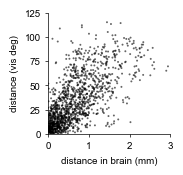

In [38]:
all_2d_dists = []
all_3d_dists = []

for data_index in range(len(dataset_ids)):
    raw_centers = np.asarray(ALL_CENTERs[data_index],dtype='object')
    raw_centers=raw_centers*5
    coords = np.array(ALL_UNIT_COORDS[data_index])  # this should be OK

    # Extract only centers that are array-like and not NaN
    centers = []
    valid_coords = []

    for c, coord in zip(raw_centers, coords):
        c_arr = np.array(c)
        if c_arr.shape == (2,) and not np.any(np.isnan(c_arr)):
            centers.append(c_arr)
            valid_coords.append(coord)

    centers = np.array(centers)
    valid_coords = np.array(valid_coords)

    if len(centers) > 1:
        for idx1, idx2 in combinations(range(len(centers)), 2):
            dist_2d = np.linalg.norm(centers[idx1] - centers[idx2])
            dist_3d = np.linalg.norm(valid_coords[idx1] - valid_coords[idx2])
            all_2d_dists.append(dist_2d)
            all_3d_dists.append(dist_3d)

r_pearson, p_pearson = pearsonr(all_3d_dists, all_2d_dists)

plt.figure(figsize=(4/2.54, 4/2.54))
ax=plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.scatter(all_3d_dists, all_2d_dists, alpha=0.6,color='black',s=2,edgecolors='none')
plt.xlabel('distance in brain (mm)')
plt.ylabel('distance (vis deg)')
#plt.title('r = {} , p = {}'.format(np.round(r_pearson,3),np.round(p_pearson,3)))
plt.xlim([0,np.max(all_3d_dists)+10])
plt.xticks([0,1000,2000,3000],[0,1,2,3])
plt.ylim([0,np.max(all_2d_dists)+10])

#plt.savefig(save_path+'retinotopy_over_brain.svg',format='svg',dpi=900)
#plt.savefig(save_path+'retinotopy_over_brain.pdf',format='pdf',dpi=900)

plt.show()
#plt.close()


In [39]:
def pearsonr_with_bootstrap(x, y, n_boot=10_000, ci=95, random_state=None):
    x = np.asarray(x)
    y = np.asarray(y)
    
    if random_state is not None:
        np.random.seed(random_state)

    # Compute observed Pearson correlation and p-value
    r, p = stats.pearsonr(x, y)

    # Bootstrap sampling
    n = len(x)
    boot_corrs = np.empty(n_boot)
    for i in range(n_boot):
        idx = np.random.randint(0, n, n)
        boot_corrs[i] = stats.pearsonr(x[idx], y[idx])[0]

    alpha = 100 - ci
    ci_bounds = np.percentile(boot_corrs, [alpha / 2, 100 - alpha / 2])

    return r, p, ci_bounds, boot_corrs


In [40]:
r, p, ci_bounds, boot_corrs = pearsonr_with_bootstrap(all_2d_dists, all_3d_dists)

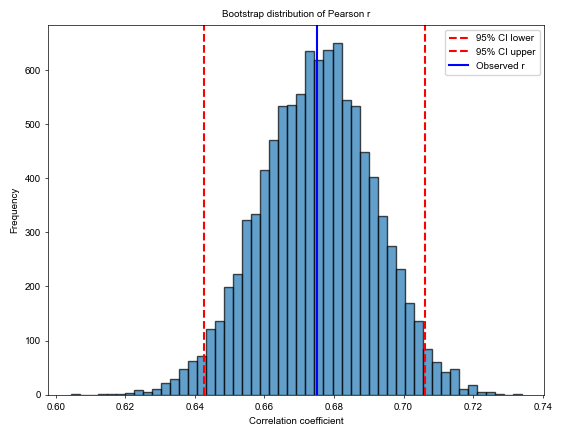

In [41]:
plt.hist(boot_corrs, bins=50, edgecolor='k', alpha=0.7)
plt.axvline(ci_bounds[0], color='red', linestyle='--', label='95% CI lower')
plt.axvline(ci_bounds[1], color='red', linestyle='--', label='95% CI upper')
plt.axvline(r, color='blue', linestyle='-', label='Observed r')
plt.title('Bootstrap distribution of Pearson r')
plt.xlabel('Correlation coefficient')
plt.ylabel('Frequency')
plt.legend()
plt.show()
#plt.close()

In [42]:
CALCIUM_IGL=np.load('CALCIUM_IGL.npy')
CALCIUM_OGL=np.load('CALCIUM_OGL.npy')
DEPTH_CALCIUM_IGL = np.random.uniform(15, 25, size=CALCIUM_IGL.shape) #The calcium imaging depth range for IGL
DEPTH_CALCIUM_OGL = np.random.uniform(0, 10, size=CALCIUM_OGL.shape) #The calcium imaging depth range for OGL

In [43]:
SEG_LABELS=['MEDULLA','PED','OGL','PLEX','IGL','CB']
SEG_COLORS=['#FF7F0E','#3a001e','#00dcc7','orange','#319fe1','purple']

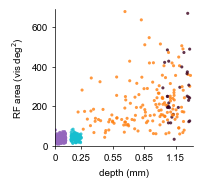

In [45]:
colors = [
    'black' if np.isnan(seg) else SEG_COLORS[int(seg) - 1] 
    for seg in RF_SEGS
]

# Scatter plot
plt.figure(figsize=(4.5/2.54, 4.5/2.54))
plt.scatter((RF_DISTS + 10) * 10,RF_SIZES, s=5, c=colors, alpha=0.8, edgecolors='none')
plt.scatter(DEPTH_CALCIUM_IGL * 10, (CALCIUM_IGL), s=5, c='#17BECF', alpha=0.8, edgecolors='none')
plt.scatter(DEPTH_CALCIUM_OGL * 10, (CALCIUM_OGL), s=5, c='#9467BD', alpha=0.8, edgecolors='none')

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks([0, 250, 550, 850, 1150],[0, 0.25, 0.55, 0.85, 1.15])
plt.xlim([0, 1310])
plt.yticks([0,200,400,600])
plt.ylim([0,690])
plt.xlabel('depth (mm)')
plt.ylabel('RF area (vis deg$^2$)')

#plt.savefig(save_path + 'RF_OVER_DEPTH.svg', format='svg', dpi=900)
#plt.savefig(save_path + 'RF_OVER_DEPTH.pdf', format='pdf', dpi=900)

plt.show()
#plt.close()


In [46]:

dist_bin_size = 15
dist_bins = np.arange(0, np.nanmax(FLAT_UNIT_DIST) + dist_bin_size, dist_bin_size)
to_fill=[]
to_fill_none=[]

for dist in range(len(dist_bins[:-1])):
    temp=[]
    temp_none=[]
    for unit in range(len(FLAT_UNIT_DIST)):
        if FLAT_UNIT_DIST[unit]>dist_bins[dist] and FLAT_UNIT_DIST[unit]<=dist_bins[dist+1]:
            temp.append(VMIs[unit])
            temp_none.append(FLAT_NONEs[unit])
    to_fill.append(np.asarray(temp))
    to_fill_none.append(np.asarray(temp_none))

to_fill_none=np.asarray(to_fill_none,dtype='object')
to_fill=np.asarray(to_fill,dtype='object') 
orig_std=np.asarray([np.nanstd(i) for i in to_fill])
orig_std_none=np.asarray([np.nanstd(i) for i in to_fill_none])
rpd=[np.nanmean(i) for i in to_fill]
rpd_none=[np.nanmean(i) for i in to_fill_none]

In [47]:
def bootstrap(data, n_bootstrap, statistic=np.nanmean):
    bootstrap_stats = []
    for _ in range(n_bootstrap):
        sample = np.random.choice(data, size=len(data), replace=True)
        bootstrap_stats.append(statistic(sample))
    return np.array(bootstrap_stats)

In [48]:
n_bootstrap = 10000  # Number of bootstrap samples
to_fill_bootstrap = [[] for _ in range(len(dist_bins) - 1)]
to_fill_bootstrap_nones=[[] for _ in range(len(dist_bins) - 1)]
for _ in range(n_bootstrap):
    # Generate random indices for resampling
    resample_indices = np.random.choice(len(VMIs), size=len(VMIs), replace=True)
    
    # Resample VMIs, FLAT_NONEs, and FLAT_UNIT_DIST using these indices
    boot_vmis = VMIs[resample_indices]
    boot_dist = FLAT_UNIT_DIST[resample_indices]
    boot_nones=FLAT_NONEs[resample_indices]
    for dist in range(len(dist_bins) - 1):
        indices = (boot_dist > dist_bins[dist]) & (boot_dist <= dist_bins[dist + 1])
        binned_vmis = boot_vmis[indices]
        binned_nones=boot_nones[indices]


        to_fill_bootstrap[dist].append(np.nanmean(binned_vmis))
        to_fill_bootstrap_nones[dist].append(np.nanmean(binned_nones))

to_fill_bootstrap = [np.array(bin) for bin in to_fill_bootstrap]
to_fill_bootstrap_nones=[np.array(bin) for bin in to_fill_bootstrap_nones]

/scratch/ipykernel_1096487/3039056395.py:18: RuntimeWarning: Mean of empty slice
  to_fill_bootstrap[dist].append(np.nanmean(binned_vmis))
/scratch/ipykernel_1096487/3039056395.py:19: RuntimeWarning: Mean of empty slice
  to_fill_bootstrap_nones[dist].append(np.nanmean(binned_nones))


In [49]:
import matplotlib.cm as cm

# Get the colormap
cmap = cm.get_cmap('coolwarm')

# Sample the min (0.0) and max (1.0) colors
min_color = cmap(0.0)  # RGBA tuple for the minimum value
max_color = cmap(1.0)  # RGBA tuple for the maximum value

/scratch/ipykernel_1096487/28838902.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('coolwarm')


In [50]:
def get_sem(arr):
    arr = np.asarray(arr)
    valid = ~np.isnan(arr)
    n = np.sum(valid)
    if n > 1:
        return np.nanstd(arr) / np.sqrt(n)
    else:
        return np.nan  # Avoid division by 0

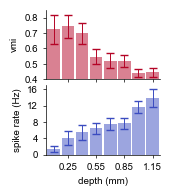

In [53]:
show_stds = True  # Set to False for no error bars
to_boot = True    # Bootstrap choice
use_sem = False  # set to True to show SEM instead of STD

if to_boot:
    std_vis_ratios = np.asarray([
        get_sem(bin) if use_sem else np.nanstd(bin) for bin in to_fill_bootstrap
    ])
    std_nones = np.asarray([
        get_sem(bin) if use_sem else np.nanstd(bin) for bin in to_fill_bootstrap_nones
    ])
else:
    std_vis_ratios = np.asarray([
        get_sem(bin) if use_sem else np.nanstd(bin) for bin in to_fill
    ])
    std_nones = np.asarray([
        get_sem(bin) if use_sem else np.nanstd(bin) for bin in to_fill_none
    ])

# Replace NaNs for plotting
std_vis_ratios = np.nan_to_num(std_vis_ratios)
std_nones = np.nan_to_num(std_nones)

# === Bin positions (centered bars, same x for overlay) ===
start_from = 0
bin_centers = dist_bins[start_from:-1] + (dist_bin_size / 2)
bar_width = dist_bin_size * 0.9  # full bin width

# === Create Figure with exact size ===
fig, axs = plt.subplots(
    2, 1,  # 2 rows, 1 column
    figsize=(3.879/2.54, 4.5/2.54),  
    sharex=True
)
# === Style common to both plots ===
for ax in axs:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim([-1, 120])

# === Plot 1: Visual Modulation Index ===
ax1 = axs[0]
if show_stds:
    ax1.bar(
        bin_centers,
        rpd[start_from:],
        width=bar_width,
        yerr=std_vis_ratios[start_from:],
        capsize=3,
        color=max_color,
        alpha=0.5,
        error_kw={'ecolor': max_color, 'elinewidth': 0.7}
    )
else:
    ax1.bar(
        bin_centers,
        rpd[start_from:],
        width=bar_width,
        color=max_color,
        alpha=0.5
    )
ax1.set_ylabel('vmi', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_yticks([0.4,0.5,0.6,0.7,0.8])
ax1.set_yticklabels([0.40,0.50,0.60,0.70,0.80])
ax1.set_ylim([0.4, 0.85])

# === Plot 2: Baseline Firing Rate ===
ax2 = axs[1]
if show_stds:
    ax2.bar(
        bin_centers,
        rpd_none[start_from:],
        width=bar_width,
        yerr=std_nones[start_from:],
        capsize=3,
        color=min_color,
        alpha=0.5,
        error_kw={'ecolor': min_color, 'elinewidth': 0.7}
    )
else:
    ax2.bar(
        bin_centers,
        rpd_none[start_from:],
        width=bar_width,
        color=min_color,
        alpha=0.5
    )
ax2.set_ylabel('spike rate (Hz)', color='black')
ax2.tick_params(axis='y', labelcolor='black')
ax2.set_yticks([0, 4, 8, 12, 16])
ax2.set_xlabel('depth (mm)')
ax2.set_xticks(bin_centers[1::2])
ax2.set_xticklabels([0.25, 0.55, 0.85, 1.15])

# === Remove internal whitespace but preserve figsize ===
plt.tight_layout(pad=0.05)

# === Save ===
#fig.savefig(save_path + 'visual_modulation_bars_separate.svg', format='svg', dpi=600)
#fig.savefig(save_path + 'visual_modulation_bars_separate.pdf', format='pdf', dpi=600)

plt.show()
#plt.close()